# Does fouling follow the time the ship sits idle?

**The idea.** Gupta et al. (2022) use an assumption from Malone et al. (1981): a hull fouls while the ship is nearly still, and not while it sails above 3 kn. If that holds for Kensas, our fouling indicator should climb as idle time adds up, and step up after long stays.

**Short answer: this data does not show that.**
- One long stay clearly fits the idea (23 Jun – 10 Jul, laden). The same stay in ballast does not. Over all stays, both measures rise in only 2 of 6 comparisons.
- Cumulative idle time predicts fouling no better than the calendar date, and both predict it poorly.
- Week by week the fouling indicator swings far more than real fouling could. So the monthly Aug–Sep number is less solid than it looks.

Run from anywhere after `prepare_features.py` and `submission.py`. Nothing here changes the pipeline. It writes one figure: `plots4report/fouling_vs_idle_time.png`.

## 1. The three things we compare

| Measure | What it is | How to read it |
|---|---|---|
| **Cumulative idle time** | Hours so far in the year with GPS speed under 3 kn | Can only go up |
| **Fouling indicator** | % extra power compared with the reference period (1 Jan – 23 Jun), after correcting for speed, loading, wind and waves. From `submission.py`, clean rows only | 0 = like the reference period, +20 = needs 20 % more power |
| **Propeller slip** | How far the ship falls short of the distance the propeller "should" push it: 1 − GPS speed / (pitch × rpm) | Higher = ship pushes harder for the same distance |

**Why slip is included.** The fouling indicator after 10 Jul depends on estimated power and a corrected speed log. Slip uses neither, only GPS and engine rpm, so it is a separate check. It is rougher, because weather and currents also move it.

**Why laden and ballast are always kept apart.** A heavy ship and a light ship behave differently, so comparing across them would mostly show the loading change.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

ROOT = ".." if os.path.exists("../data") else "."
PITCH_M, KN_TO_MS = 4.58, 0.5144
IDLE_KN, MIN_STAY_DAYS = 3, 5
LADEN, BALLAST, INK, INK2, GREY, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

m = pd.read_csv(f"{ROOT}/data/processed/model_table.csv", index_col="time", parse_dates=True)
f = pd.read_csv(f"{ROOT}/data/processed/submission/Kensas_Model1_Timeseries.csv")
m["fouling"], m["clean"] = f["Fouling [%Power]"].values, f["clean "].values
m = m.tz_convert(None)
m = m[m.index < "2025-01-01"]                                 # Jan 2025 has no power or engine rpm at sea

sog = m.sog_kn.asfreq("10min")
m["idle_h"] = ((sog < IDLE_KN).cumsum() / 6).reindex(m.index)  # one row = 10 minutes
m["slip"] = 100 * (1 - m.sog_kn * KN_TO_MS / (PITCH_M * m.me_rpm / 60))

clean = m[m.clean]                 # rows behind the fouling indicator
calm = m[m.steady & m.calm]        # same kind of rows for slip
print(f"idle under {IDLE_KN} kn in 2024: {m.idle_h.iloc[-1]:,.0f} h, {100 * (m.sog_kn < IDLE_KN).sum() / m.sog_kn.notna().sum():.0f} % of the rows with GPS speed")
print(f"rows: {len(clean):,} for the fouling indicator, {len(calm):,} for slip")

idle under 3 kn in 2024: 1,894 h, 23 % of the rows with GPS speed
rows: 15,463 for the fouling indicator, 16,771 for slip


## 2. Find the long stays

**What it does.** Finds stretches under 3 kn lasting at least 5 days. Moves shorter than 6 hours don't end a stay, because short shifts inside a port aren't real sailing. The two stays in late June and early July are about a day apart, so they count as one.

**Output.** A table with one row per stay.

In [2]:
low = (sog < IDLE_KN) | (sog.isna() & (sog.ffill(limit=12) < IDLE_KN))   # gaps up to 2 h don't end a stay
run = (low != low.shift()).cumsum()
parts = pd.DataFrame([(x.index[0], x.index[-1]) for _, x in sog[low].groupby(run[low])], columns=["start", "end"])
parts["group"] = (parts.start - parts.end.shift() > pd.Timedelta("6h")).cumsum()
stays = parts.groupby("group").agg(start=("start", "first"), end=("end", "last"))
stays = stays[stays.end - stays.start >= pd.Timedelta(days=MIN_STAY_DAYS)].reset_index(drop=True)
stays["group"] = (stays.start - stays.end.shift() > pd.Timedelta(days=1.5)).cumsum()     # late June + early July
stays = stays.groupby("group").agg(start=("start", "first"), end=("end", "last")).reset_index(drop=True)
stays["days"] = ((stays.end - stays.start).dt.total_seconds() / 86400).round(1)
stays.assign(start=stays.start.dt.date, end=stays.end.dt.date)

,start,end,days
0,2024-01-21,2024-02-02,12.0
1,2024-05-11,2024-05-23,11.9
2,2024-06-23,2024-07-10,16.7
3,2024-11-24,2024-11-30,5.4


## 3. Look at the whole year first

**What it does.** Puts the three measures on one timeline, as weekly medians. Grey bands are the long stays. The dashed line is 10 Jul, where power switches from the torquemeter to the estimate.

**What the idea predicts.** After each grey band, the points in the two lower panels should step up and stay up until a cleaning.

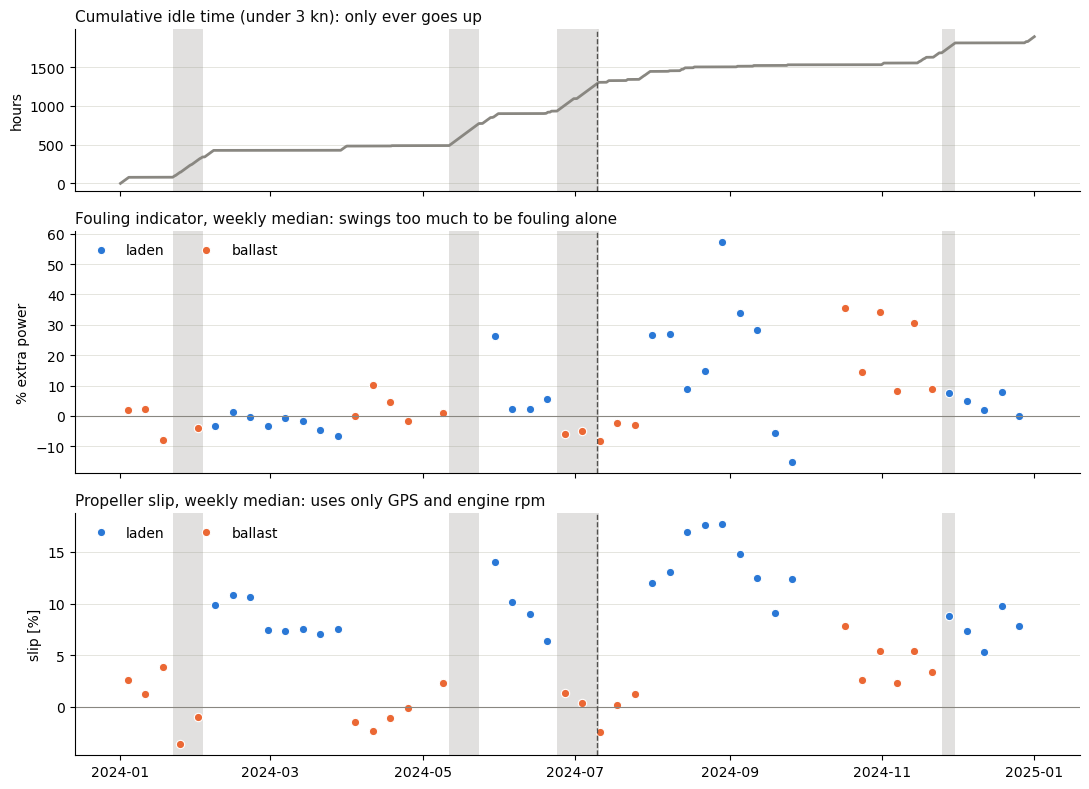

laden, Aug-Sep: weekly fouling from -15 to 57 %
ballast, Oct-Nov: weekly fouling from 8 to 36 %


In [3]:
def weekly(d, col):
    g = d.groupby([d.index.to_period("W"), "laden"])[col].agg(["median", "size"]).reset_index()
    g = g[g["size"] >= 12]
    g["mid"] = g.time.dt.start_time + pd.Timedelta(days=3)
    return g

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, height_ratios=[0.8, 1.2, 1.2], facecolor="white")
axes[0].plot(m.index, m.idle_h, color=GREY, lw=2)
axes[0].set_ylabel("hours")
axes[0].set_title("Cumulative idle time (under 3 kn): only ever goes up", loc="left", color=INK, fontsize=11)
panels = [(axes[1], clean, "fouling", "% extra power", "Fouling indicator, weekly median: swings too much to be fouling alone"),
          (axes[2], calm, "slip", "slip [%]", "Propeller slip, weekly median: uses only GPS and engine rpm")]
for ax, data, col, ylab, title in panels:
    w = weekly(data, col)
    for lad, colour, label in [(True, LADEN, "laden"), (False, BALLAST, "ballast")]:
        p = w[w.laden == lad]
        ax.plot(p.mid, p["median"], "o", color=colour, ms=6, mec="white", mew=0.8, label=label)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_ylabel(ylab)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.legend(frameon=False, loc="upper left", ncol=2)
for ax in axes:
    for _, s in stays.iterrows():
        ax.axvspan(s.start, s.end, color=GREY, alpha=0.25, lw=0)
    ax.axvline(pd.Timestamp("2024-07-10"), color=INK2, ls="--", lw=1)
    ax.yaxis.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(f"{ROOT}/plots4report/fouling_vs_idle_time.png", dpi=150)
plt.show()

w = weekly(clean, "fouling")
aug_sep = w[w.laden & (w.time.dt.start_time >= "2024-07-29") & (w.time.dt.start_time < "2024-09-30")]
oct_nov = w[~w.laden & (w.time.dt.start_time >= "2024-10-14")]
print(f"laden, Aug-Sep: weekly fouling from {aug_sep['median'].min():.0f} to {aug_sep['median'].max():.0f} %")
print(f"ballast, Oct-Nov: weekly fouling from {oct_nov['median'].min():.0f} to {oct_nov['median'].max():.0f} %")

**How to read it.**
- Real fouling builds up slowly and only drops at a cleaning. It can't go from +57 % to −15 % in a month, or alternate between about 10 % and 30 % from week to week. So these swings come from something else as well, such as voyage conditions or the speed and power estimates.
- The monthly Aug–Sep figure is a median across those swings, so treat it as a rough level and not a precise rate.
- Slip is smoother. Laden, it rises in August, and it is back down by mid-September, with no known cleaning in between.
- One pattern is worth a closer look. Laden slip starts high after the February, May–June and July–August restarts, then falls over several weeks. Soft fouling wearing off once the ship sails would look like this, but so would route and weather changes. It is an observation, not a result.

## 4. Test A: does idle time predict fouling better than the date?

**What it does.** Tries to predict the daily fouling indicator three ways, and scores each on weeks it has not seen (the same week-based split as our models):
1. loading only (laden or ballast), the starting point
2. loading + cumulative idle time
3. loading + date

**Why compare with the date.** Anything that grows through the year will seem to "explain" a rising trend. Idle time only earns credit if it does better than the calendar.

**Output.** One score per method. The score is out-of-sample R²: 1 = perfect, 0 = no better than guessing the average, below 0 = worse than guessing the average.

In [4]:
day = clean.groupby(clean.index.normalize()).agg(fouling=("fouling", "median"), rows=("fouling", "size"), laden=("laden", "mean"),
                                                  idle_h=("idle_h", "last"), week=("week", "first"))
day = day[day.rows >= 6]
day["laden"] = day.laden > 0.5
day["date"] = (day.index - pd.Timestamp("2024-01-01")).days

def score(d, cols):
    X, y, pred = d[cols].astype(float).values, d.fouling.values, np.zeros(len(d))
    for train, test in GroupKFold(6).split(X, y, d.week):
        pred[test] = LinearRegression().fit(X[train], y[train]).predict(X[test])
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

periods = {"All of 2024": day, "Jan to Oct (before the drop)": day[day.index < "2024-11-01"], "After the reference period": day[day.index >= "2024-06-24"]}
methods = {"loading only": ["laden"], "loading + idle time": ["laden", "idle_h"], "loading + date": ["laden", "date"]}
table_a = pd.DataFrame({p: {k: score(d, c) for k, c in methods.items()} for p, d in periods.items()}).round(2)
print(f"correlation between cumulative idle time and date: {day.idle_h.corr(day.date):.2f}")
table_a

correlation between cumulative idle time and date: 0.97


,All of 2024,Jan to Oct (before the drop),After the reference period
loading only,-0.08,-0.09,-0.10
loading + idle time,0.10,0.12,-0.17
loading + date,0.10,0.17,-0.15


**How to read it.**
- Idle time and date are nearly the same line (correlation close to 1), so this data can hardly tell them apart.
- Idle time doesn't beat the date in any period. Both scores stay low, so neither explains much of the indicator.
- After the reference period the scores are negative. From there fouling falls while idle time keeps rising, which the idea can't explain without a cleaning.

## 5. Test B: is fouling higher after a long stay?

**What it does.** For each long stay, takes the nearest same-loading sailing before and after it (14 days of it and at least 5 different days, searching up to 90 days away), and compares the medians. Both the fouling indicator and slip get the same comparison.

**Why same loading.** The ship often changes between laden and ballast during a stay, so the "before" and "after" can be weeks apart. The date columns show the real windows.

**What the idea predicts.** A positive change in both measures.

**Output.** One row per stay and loading condition.

In [5]:
def closest_days(d, last):
    # sailing closest to the stay: 14 days of it, widened if needed to at least 5 different days
    days = d.index.normalize().unique().sort_values(ascending=not last)
    edge = days[0] + pd.Timedelta(days=-14 if last else 14)
    if len(days) >= 5:
        edge = min(edge, days[4]) if last else max(edge, days[4])
    return d[d.index.normalize() >= edge] if last else d[d.index.normalize() <= edge]

def nearest(d, stay, lad):
    d = d[d.laden == lad]
    before = d[(d.index < stay.start) & (d.index >= stay.start - pd.Timedelta(days=90))]
    after = d[(d.index > stay.end) & (d.index <= stay.end + pd.Timedelta(days=90))]
    if len(before) < 30 or len(after) < 30:
        return None
    return closest_days(before, last=True), closest_days(after, last=False)

rows = []
for _, stay in stays.iterrows():
    for lad in (True, False):
        fo, sl = nearest(clean, stay, lad), nearest(calm, stay, lad)
        if fo is None or sl is None:
            continue
        rows.append({"stay": f"{stay.start:%d %b} - {stay.end:%d %b}", "days": stay.days, "loading": "laden" if lad else "ballast",
                     "before": f"{fo[0].index[0]:%d %b} - {fo[0].index[-1]:%d %b}", "after": f"{fo[1].index[0]:%d %b} - {fo[1].index[-1]:%d %b}",
                     "fouling change": fo[1].fouling.median() - fo[0].fouling.median(), "slip change": sl[1].slip.median() - sl[0].slip.median()})
table_b = pd.DataFrame(rows)
table_b["both up"] = (table_b["fouling change"] > 0) & (table_b["slip change"] > 0)
print(f"both measures up in {table_b['both up'].sum()} of {len(table_b)} comparisons")
table_b.round(1)

both measures up in 2 of 6 comparisons


,stay,days,loading,before,after,fouling change,slip change,both up
0,21 Jan - 02 Feb,12.0,ballast,12 Jan - 21 Jan,01 Apr - 15 Apr,11.1,-3.9,False
1,11 May - 23 May,11.9,laden,14 Mar - 28 Mar,29 May - 12 Jun,6.6,1.5,True
2,11 May - 23 May,11.9,ballast,28 Apr - 11 May,30 Jun - 14 Jul,-6.6,-3.5,False
3,23 Jun - 10 Jul,16.7,laden,09 Jun - 23 Jun,31 Jul - 11 Aug,24.9,4.4,True
4,23 Jun - 10 Jul,16.7,ballast,28 Apr - 11 May,10 Jul - 24 Jul,-3.4,-2.1,False
5,24 Nov - 30 Nov,5.4,laden,20 Sep - 24 Nov,30 Nov - 14 Dec,16.7,-3.0,False


**How to read it.** Change is in points: +25 under fouling means the indicator is 25 points higher after the stay.
- **Clear fit:** 23 Jun – 10 Jul, laden. Both measures rise. This is the case that started the idea.
- **Same stay, ballast:** both measures fall. A hull can't foul only when laden, although the ballast "before" window is about two months earlier, so this comparison is weak.
- **January, ballast:** the two measures disagree.
- **November, laden:** the two measures disagree, and the result depends on the window. The "before" is mostly late September, when the indicator was unusually low. Other reasonable choices of that window gave about −15 and about 0 instead of about +17 points, which shows how unstable this measure is.

## 6. What this means

**What we can say**
- The largest rise follows the longest stay before August (23 Jun – 10 Jul), and both measures show it when laden. That's consistent with idle fouling, but it's one case.
- Across the year, idle time doesn't explain the indicator better than the date.
- So we **can't claim** that idle time drives fouling on this ship, and we can't rule it out either.

**What changes for the report**
- Don't write that fouling grows after long stays as a finding. Write it as a hypothesis from the literature that this data only partly supports.
- Report the monthly Aug–Sep values with the weekly spread next to them.

**Limits of this test**
- Few events: 4 long stays, with 6 comparisons.
- Two of the stays are inside the reference period, where the indicator sits near 0 largely by construction. Slip doesn't have this problem.
- The windows are far apart and differ in route, weather and water temperature. Water temperature affects growth, but it is missing for most of the June–July stay.
- Without cleaning dates we can't reset the count after a cleaning, as Gupta et al. do. A cleaning in November would explain the drop.
- Kensas is a full-form ship, so some fouling may also happen above 3 kn (the caveat in Gupta et al.).

**Next**
1. Find out why the weekly indicator swings so much. This matters more than the idle question.
2. Get the cleaning dates from the TA, then rerun this with the count reset at each cleaning.